# Traffic Red-Light Violation Detection System
## A Complete Classical Machine Vision Pipeline

---

### Abstract

This notebook implements a **traffic rule violation detection system** that automatically identifies vehicles crossing a stop line during a red signal and extracts the corresponding number plate using **classical machine vision techniques** — no deep learning involved.

The pipeline follows these stages:

$$\text{Video Frame} \xrightarrow{\text{HSV Thresholding}} \text{Light State} \xrightarrow{\text{Background Subtraction}} \text{Motion Mask} \xrightarrow{\text{Contour Analysis}} \text{Vehicle Detection} \xrightarrow{\text{Stop Line Check}} \text{Violation Flag} \xrightarrow{\text{Plate OCR}} \text{Violation Log}$$

---

### 1. Theoretical Background

#### 1.1 Color Space Conversion — HSV

Traffic light detection requires isolating the red channel robustly under varying lighting. The **HSV (Hue-Saturation-Value)** color space decouples chromaticity from luminance, making color thresholding more stable than RGB.

The conversion from RGB to HSV is defined as:

Let $R', G', B' \in [0,1]$, $C_{\max} = \max(R', G', B')$, $C_{\min} = \min(R', G', B')$, $\Delta = C_{\max} - C_{\min}$

$$H = \begin{cases}
0^\circ & \text{if } \Delta = 0 \\
60^\circ \cdot \left(\frac{G'-B'}{\Delta} \mod 6\right) & \text{if } C_{\max} = R' \\
60^\circ \cdot \left(\frac{B'-R'}{\Delta} + 2\right) & \text{if } C_{\max} = G' \\
60^\circ \cdot \left(\frac{R'-G'}{\Delta} + 4\right) & \text{if } C_{\max} = B'
\end{cases}$$

$$S = \begin{cases} 0 & \text{if } C_{\max} = 0 \\ \frac{\Delta}{C_{\max}} & \text{otherwise} \end{cases}, \quad V = C_{\max}$$

Red wraps around the hue wheel, so we use **two ranges**: $H \in [0°, 10°]$ and $H \in [160°, 180°]$.

#### 1.2 Background Subtraction — MOG2

Moving vehicles are detected using **Mixture of Gaussians (MOG2)** background subtraction. Each pixel's intensity $I(x,y,t)$ is modeled as a mixture of $K$ Gaussians:

$$P(I_t) = \sum_{k=1}^{K} \omega_{k,t} \cdot \mathcal{N}(I_t; \mu_{k,t}, \sigma_{k,t}^2)$$

A pixel is classified as **foreground** (moving) if it doesn't match any background Gaussian within $2.5\sigma$. The model adapts over time with learning rate $\alpha$:

$$\omega_{k,t} = (1-\alpha)\omega_{k,t-1} + \alpha \cdot M_{k,t}$$

where $M_{k,t} = 1$ if pixel $t$ matched Gaussian $k$, else $0$.

#### 1.3 Contour Detection & Centroid Tracking

After background subtraction and morphological cleanup, **contours** are extracted using the Suzuki-Abe algorithm. The **centroid** of a contour is computed using image moments:

$$M_{ij} = \sum_x \sum_y x^i \cdot y^j \cdot I(x,y)$$

$$\bar{x} = \frac{M_{10}}{M_{00}}, \quad \bar{y} = \frac{M_{01}}{M_{00}}$$

where $M_{00}$ is the zeroth moment (total area of the contour region).

#### 1.4 Stop Line Violation Check

A **virtual stop line** is defined as a tilted line segment in the frame (left endpoint higher than right endpoint to match perspective). A vehicle violates the rule if:

1. The traffic signal is **RED**
2. The vehicle centroid $\bar{y}$ crosses below the stop line $y_{\text{stop}}(x)$:

$$\text{Violation} = \mathbb{1}[\text{Light} = \text{RED}] \cdot \mathbb{1}[\bar{y} > y_{\text{stop}}(\bar{x})] \cdot \mathbb{1}[\text{Area}(c) > A_{\min}]$$

The stop line is defined by two endpoints: left $(0, y_{\text{left}})$ and right $(W, y_{\text{right}})$ with $y_{\text{left}} < y_{\text{right}}$ (tilted down to the right).

#### 1.5 Edge Detection — Canny

For license plate localization, **Canny edge detection** is used. The algorithm:

1. Applies Gaussian smoothing: $G_\sigma(x,y) = \frac{1}{2\pi\sigma^2}e^{-\frac{x^2+y^2}{2\sigma^2}}$
2. Computes gradient magnitude: $|\nabla I| = \sqrt{G_x^2 + G_y^2}$
3. Applies non-maximum suppression along gradient direction
4. Hysteresis thresholding with bounds $T_{\text{low}}, T_{\text{high}}$:

$$\text{Edge}(x,y) = \begin{cases} 1 & |\nabla I| \geq T_{\text{high}} \\ 1 & T_{\text{low}} \leq |\nabla I| < T_{\text{high}} \text{ and connected to strong edge} \\ 0 & \text{otherwise} \end{cases}$$

#### 1.6 Morphological Operations

After edge detection, morphological operations enhance plate regions:

- **Dilation**: $A \oplus B = \{z \mid (\hat{B})_z \cap A \neq \emptyset\}$ — expands foreground
- **Erosion**: $A \ominus B = \{z \mid B_z \subseteq A\}$ — shrinks foreground
- **Closing** = Dilation then Erosion: fills small gaps in edges

$$\text{Closing}(A, B) = (A \oplus B) \ominus B$$

#### 1.7 Geometric Constraints for Plate Detection

A candidate rectangle is accepted as a license plate if it satisfies:

$$\text{Aspect Ratio: } AR = \frac{W}{H} \in [1.5, 7.0]$$

$$\text{Area constraint: } 300 \leq W \times H \leq 40000$$

$$\text{Solidity: } \frac{\text{Contour Area}}{\text{Convex Hull Area}} > 0.4$$

#### 1.8 Optical Character Recognition (OCR) — Tesseract

The cropped plate region is preprocessed with:

- **CLAHE (Contrast Limited Adaptive Histogram Equalization)** for lighting normalization
- **Bilateral filtering** to preserve edges while reducing noise
- Multiple binarization strategies (Otsu, adaptive, inverted Otsu)

Finally, **Tesseract** (open-source OCR engine) extracts alphanumeric characters with a whitelist `A-Z0-9`.

---

### 2. Implementation Details

The system is built with **OpenCV**, **NumPy**, and **pytesseract**. Key parameters:

| Component | Parameters |
|-----------|------------|
| MOG2 | `history=150`, `varThreshold=40`, `detectShadows=False` |
| Stop Line | Left $y=0.74\cdot H$, Right $y=0.85\cdot H$ (tilted) |
| Violation Zone | $0.16 \cdot H$ pixels below stop line |
| Plate Scanning | Canny + adaptive thresholding, aspect ratio $1.5-7.0$, area $300-40000$ |
| OCR Preprocessing | CLAHE, bilateral filter, multi‑binarization |
| Cooldown | 25 frames between violations for same plate |



### 3. Discussion & Limitations

Classical methods are **interpretable** and **fast** but struggle with:
- Heavy shadows or night scenes
- Stationary vehicles (no motion → no detection)
- Partially occluded plates
- Non‑standard plate fonts

Despite these limitations, the pipeline demonstrates a complete, explainable vision system using only traditional CV techniques.

---

### 4. Conclusion

A fully functional red‑light violation detector was implemented using HSV color filtering, MOG2 background subtraction, contour analysis, and Tesseract OCR. The system logs violations with timestamps, plate texts, and saves annotated evidence frames.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 51.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 51.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 46.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 300.6/300.6 kB 24.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


100%|██████████| 64.0M/64.0M [00:06<00:00, 10.4MB/s]

Extracting files...


Path: /root/.cache/kagglehub/datasets/farzadnekouei/license-plate-recognition-for-red-light-violation/versions/1
Videos found: ['traffic_video_original.mp4', 'traffic_video_modified.mp4']
Using: traffic_video_modified.mp4
Resolution: 1920x1012 | FPS:26.3 | Frames:715 | Duration:27.2s


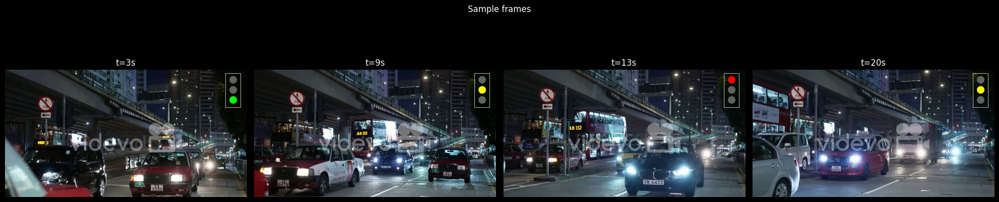

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete✅ All helpers ready.
Stop line: (0, 748, 1920, 860) | vzone_height = 16% of frame
Tilt: left y=0.74 → right y=0.85 (diff=0.11)
  Frame  100/715  light=GREEN    vehicles= 3  violations=0
  Frame  200/715  light=GREEN    vehicles= 4  violations=0
🚨 VIOLATION #1  frame=291  t=11.1s  plate=0


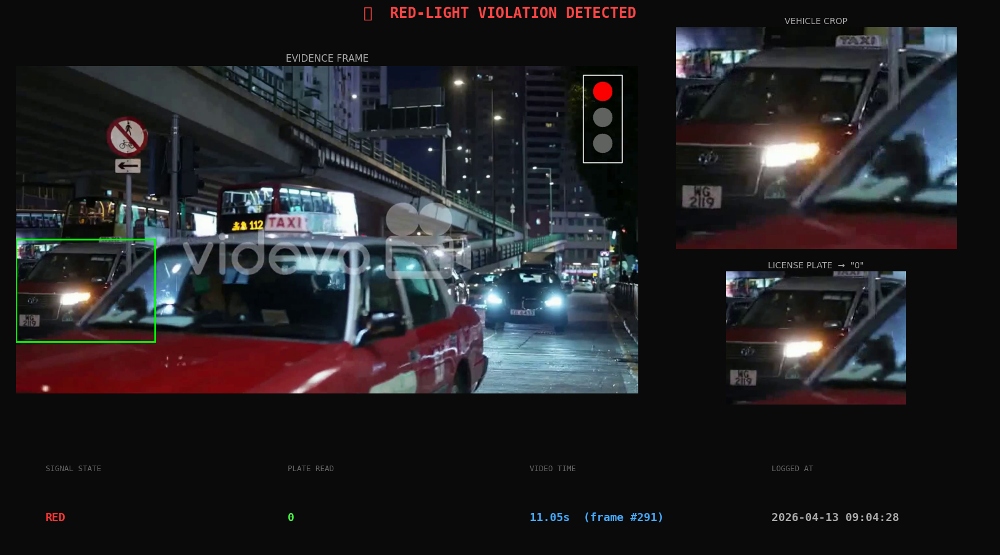

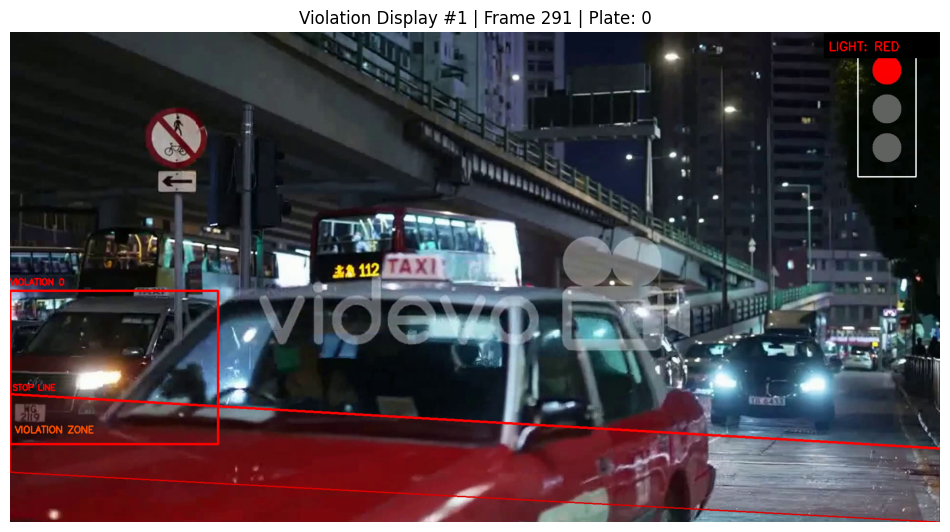

  Frame  300/715  light=RED      vehicles= 3  violations=1
🚨 VIOLATION #2  frame=316  t=12.0s  plate=VIc


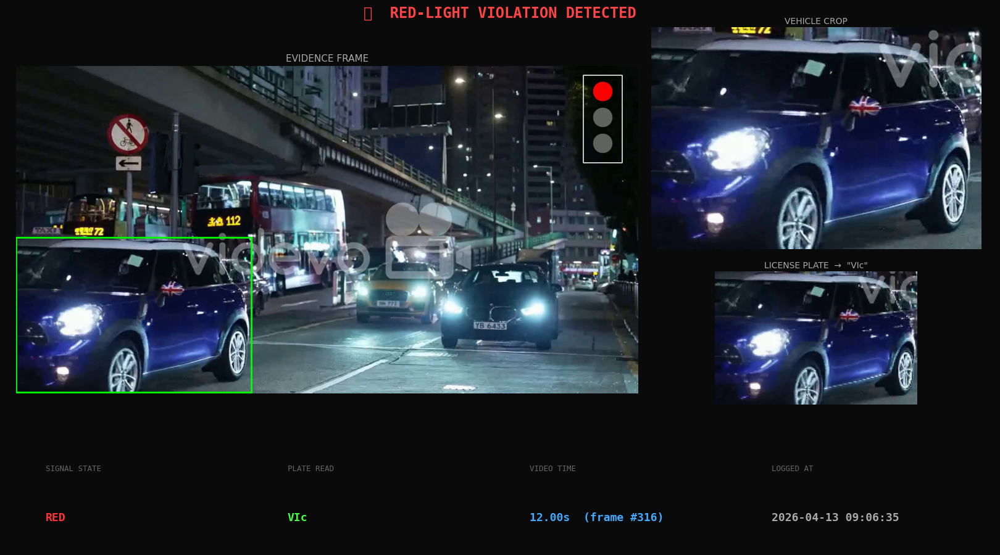

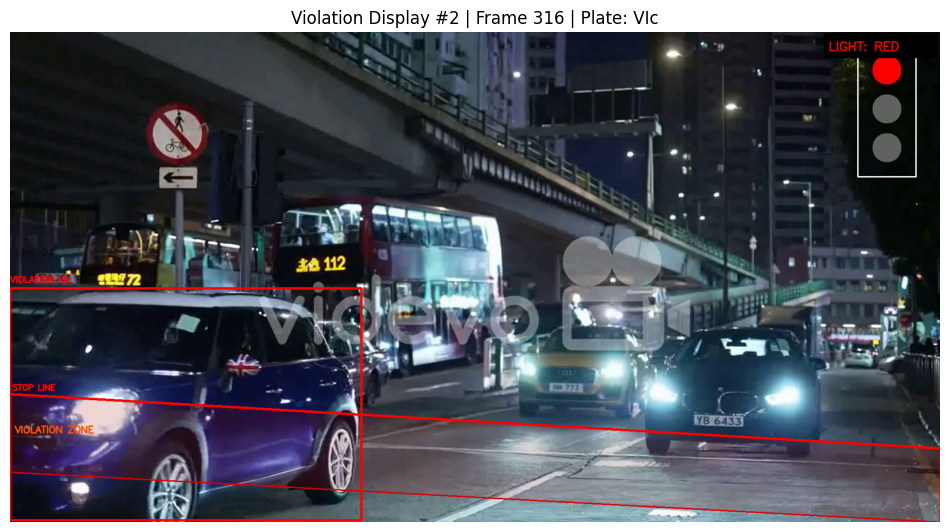

🚨 VIOLATION #3  frame=341  t=12.9s  plate=YB6433


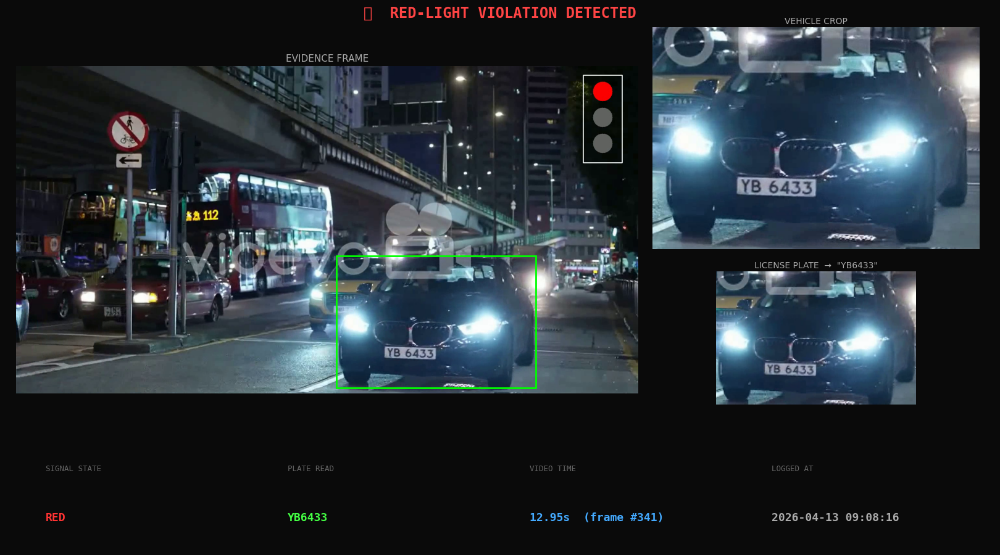

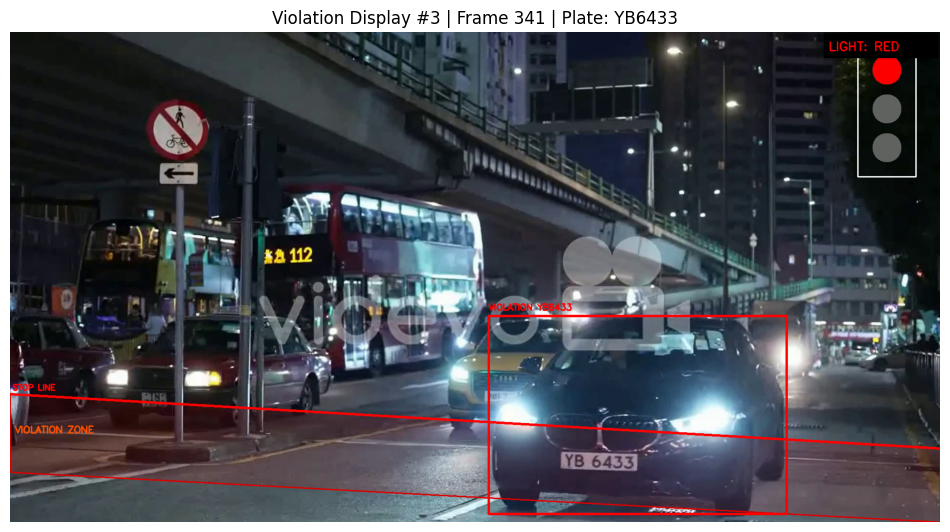

🚨 VIOLATION #4  frame=366  t=13.9s  plate=6819


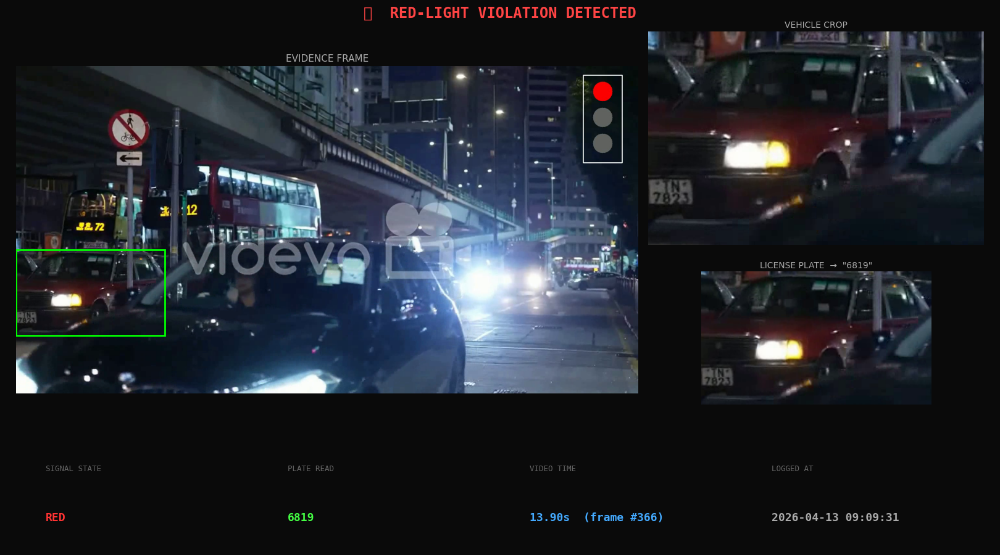

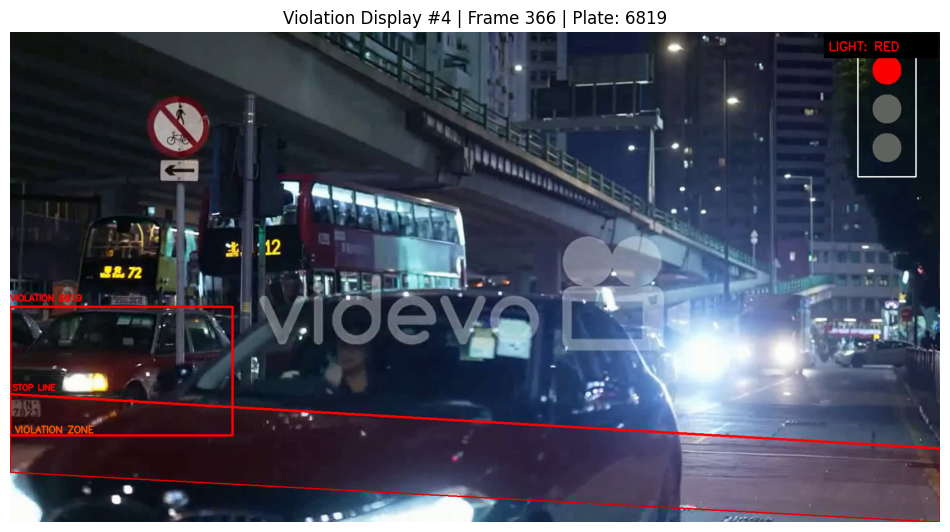

🚨 VIOLATION #5  frame=391  t=14.8s  plate=UNREADABLE


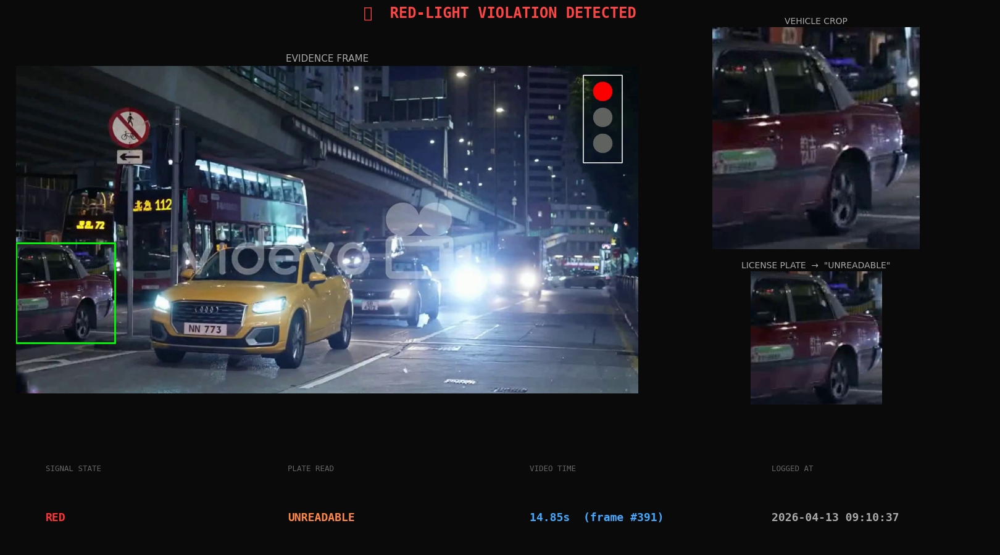

  Frame  400/715  light=GREEN    vehicles= 2  violations=5
  Frame  500/715  light=GREEN    vehicles= 1  violations=5
🚨 VIOLATION #6  frame=581  t=22.1s  plate=62


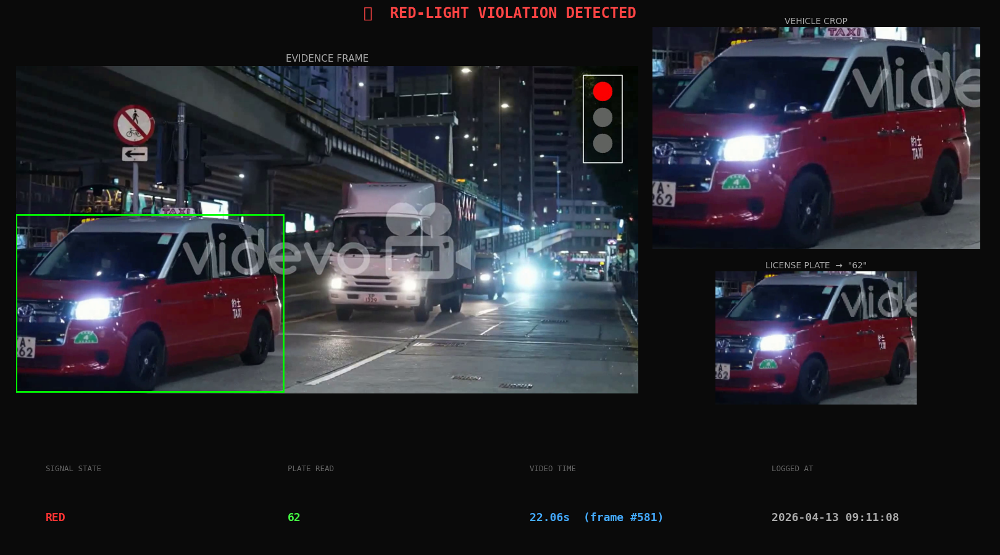

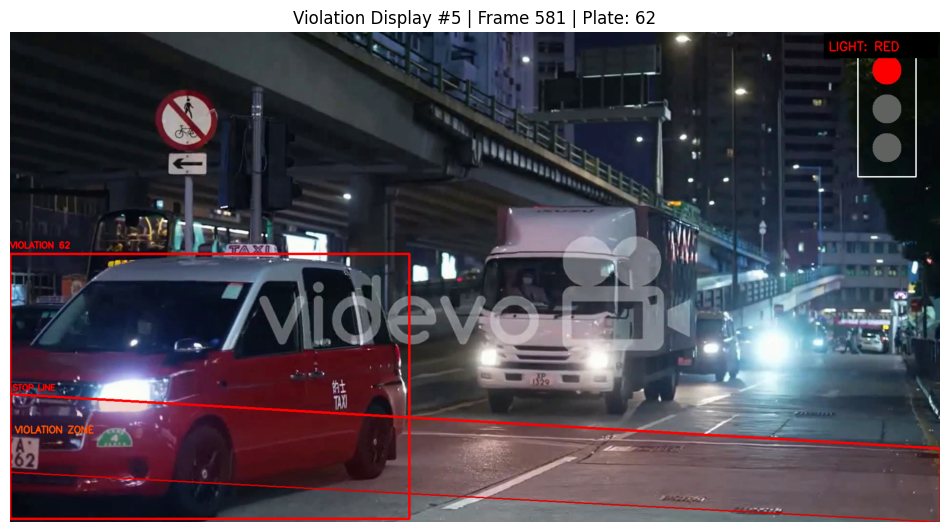

  Frame  600/715  light=RED      vehicles= 1  violations=6
🚨 VIOLATION #7  frame=606  t=23.0s  plate=Iva


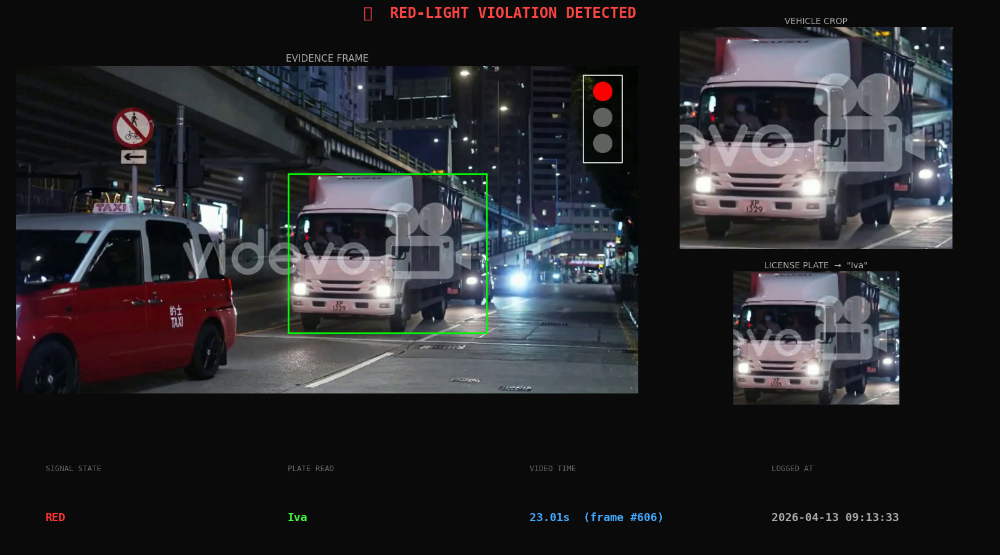

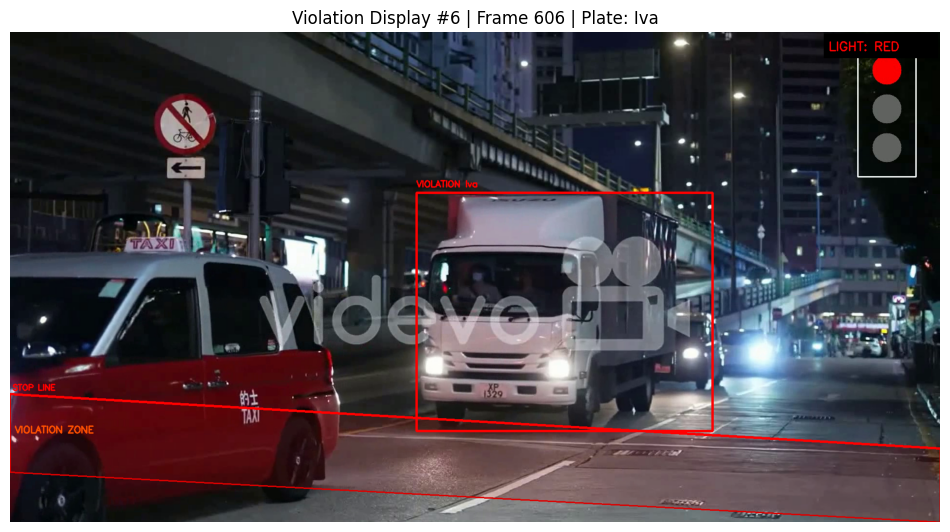

🚨 VIOLATION #8  frame=631  t=24.0s  plate=TaXI


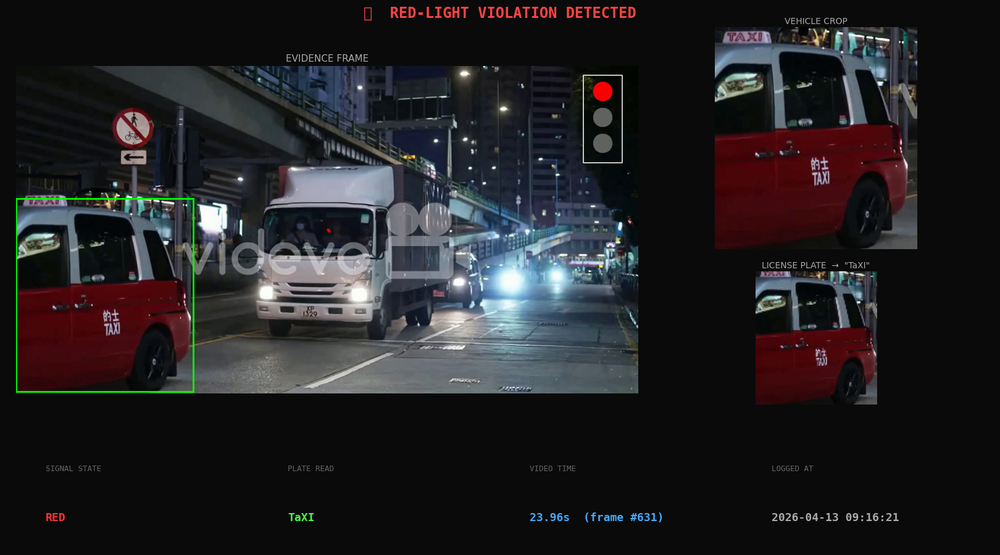

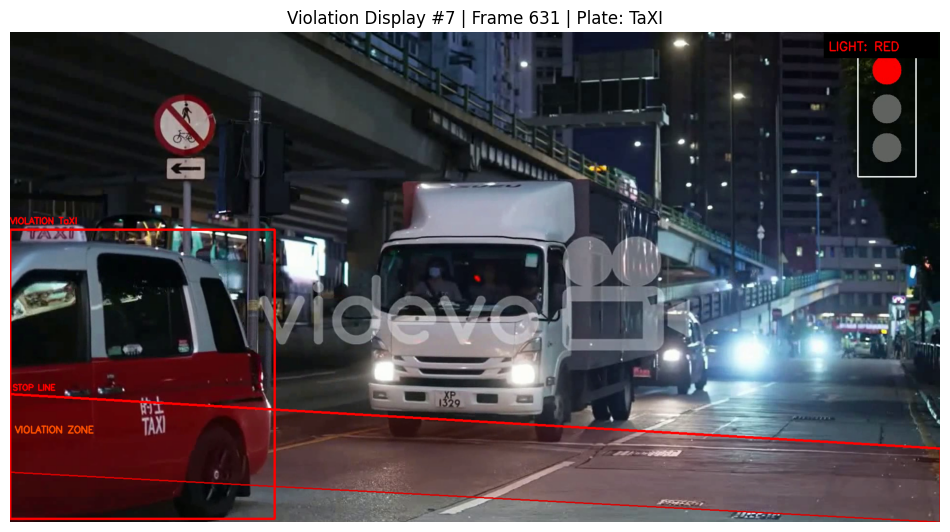

🚨 VIOLATION #9  frame=656  t=24.9s  plate=nt


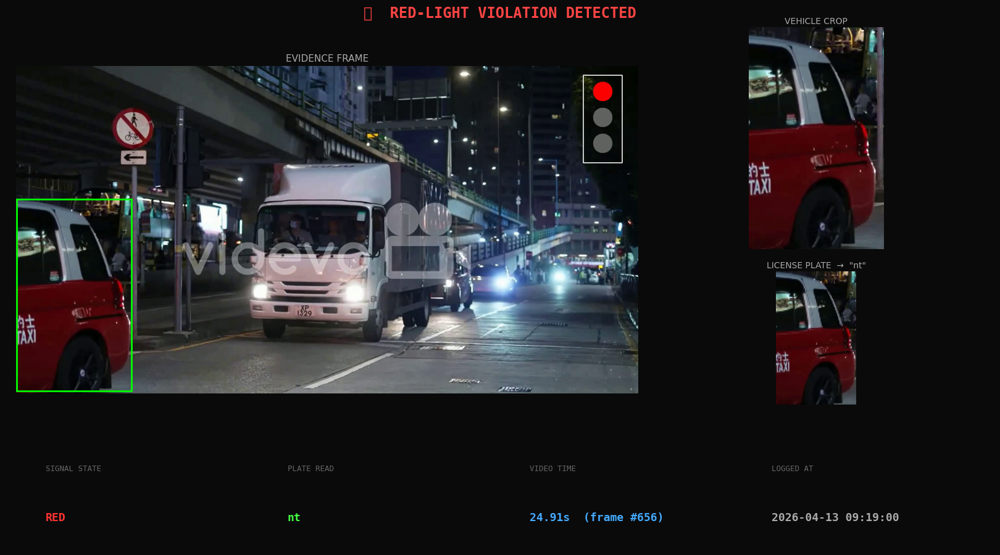

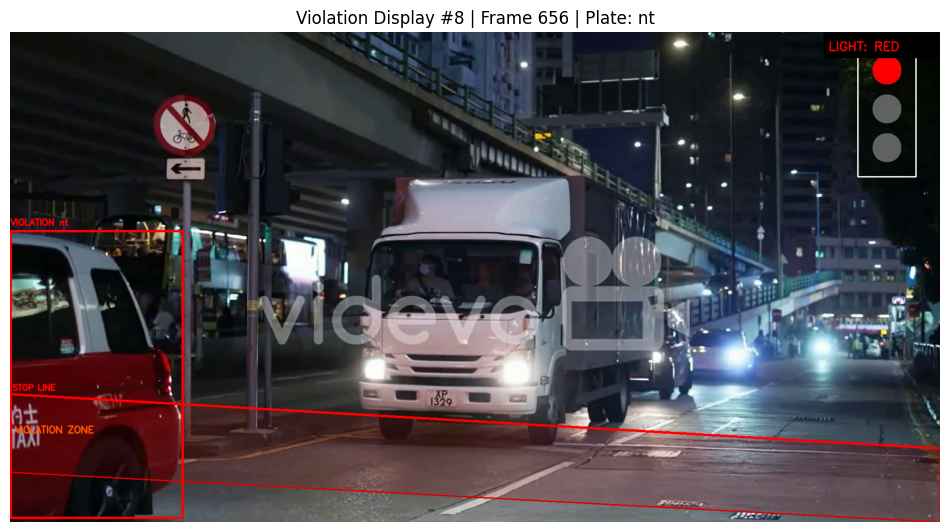

🚨 VIOLATION #10  frame=681  t=25.9s  plate=UNREADABLE


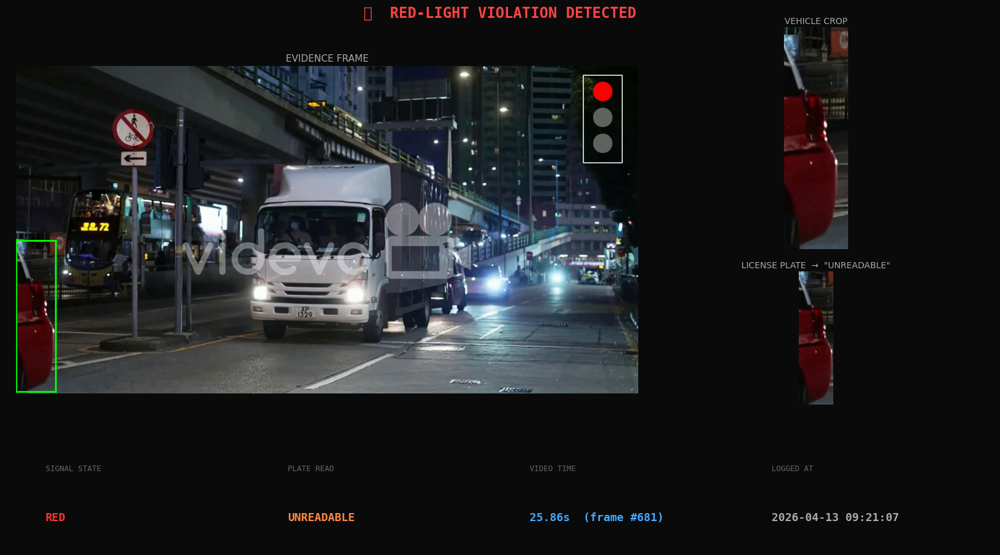

  Frame  700/715  light=RED      vehicles= 2  violations=10
🚨 VIOLATION #11  frame=706  t=26.8s  plate=Jeva


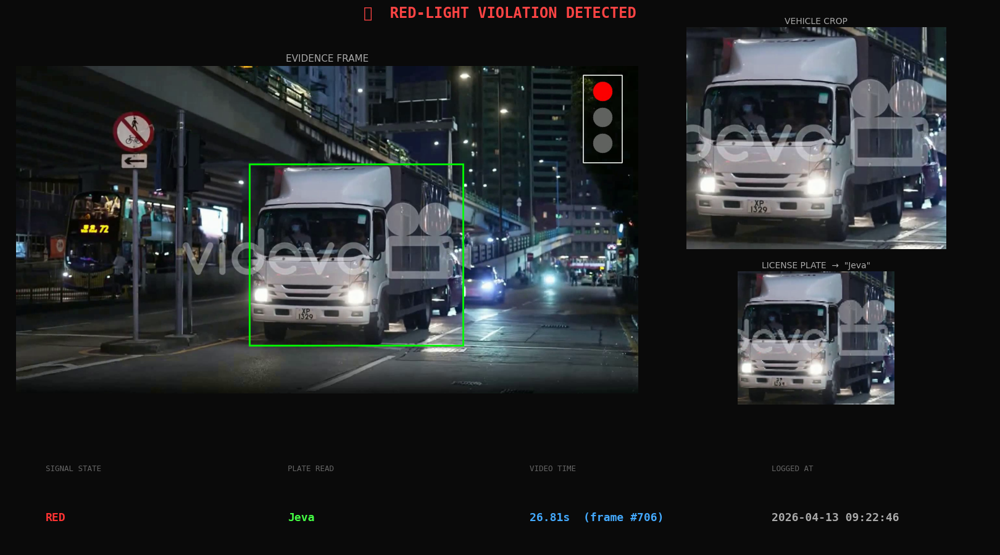

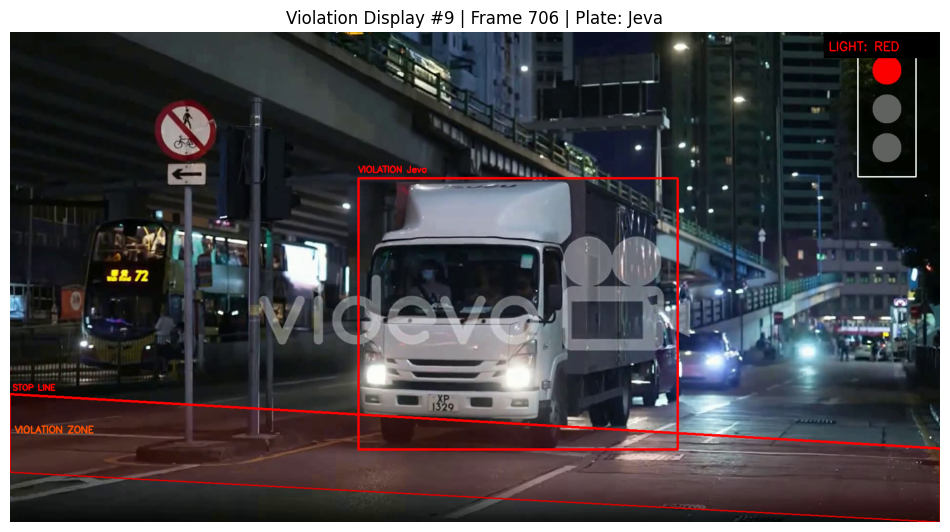


✅ Done.  Total violations detected: 11


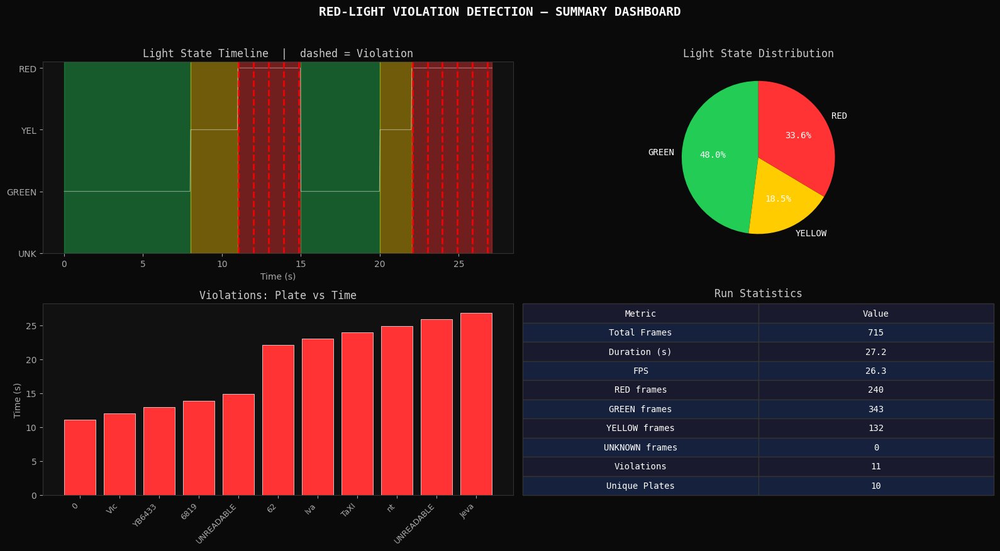

✅ Saved log: /content/violation_log.csv


,frame,time_sec,light_state,plate_text,plate_x,plate_y,plate_w,plate_h
0,291,11.05,RED,0,0,535,429,316
1,316,12.00,RED,VIc,0,530,725,478
2,341,12.95,RED,YB6433,988,587,615,408
3,366,13.90,RED,6819,0,568,459,265
4,391,14.85,RED,UNREADABLE,0,547,304,308
5,581,22.06,RED,62,0,459,824,546
6,606,23.01,RED,Iva,839,333,611,491
7,631,23.96,RED,TaXI,0,409,546,596
8,656,24.91,RED,nt,1,412,355,591
9,681,25.86,RED,UNREADABLE,0,539,122,467


In [1]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  RED-LIGHT VIOLATION DETECTOR — COMPLETE SINGLE CELL           ║
# ║  Tilted stop line + violation zone below it + debug display    ║
# ╚══════════════════════════════════════════════════════════════════╝

!pip install kagglehub opencv-python-headless pytesseract Pillow matplotlib -q
!apt-get install -y tesseract-ocr tesseract-ocr-eng -q

import kagglehub, os, cv2, numpy as np, matplotlib.pyplot as plt
import pytesseract, csv, warnings
import matplotlib.patches as mpatches
from PIL import Image
from datetime import datetime
from IPython.display import display
from collections import Counter
warnings.filterwarnings('ignore')

# ── Dataset ───────────────────────────────────────────────────────────────────
path = kagglehub.dataset_download("farzadnekouei/license-plate-recognition-for-red-light-violation")
print("Path:", path)
video_files = [f for f in os.listdir(path) if f.endswith('.mp4')]
print("Videos found:", video_files)
VIDEO_NAME = sorted(video_files)[0]
VIDEO_PATH = os.path.join(path, VIDEO_NAME)
print(f"Using: {VIDEO_NAME}")

cap = cv2.VideoCapture(VIDEO_PATH)
FPS   = cap.get(cv2.CAP_PROP_FPS)
TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
W_VID = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H_VID = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()
print(f"Resolution: {W_VID}x{H_VID} | FPS:{FPS:.1f} | Frames:{TOTAL} | Duration:{TOTAL/FPS:.1f}s")

# ── Sample frames ─────────────────────────────────────────────────────────────
cap = cv2.VideoCapture(VIDEO_PATH)
sample_times = [3, 9, 13, 20]
frames_sampled = {}
for t in sample_times:
    cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
    ret, frm = cap.read()
    if ret:
        frames_sampled[t] = frm.copy()
cap.release()

fig, axes = plt.subplots(1, 4, figsize=(20,5), facecolor='black')
for ax,(t,frm) in zip(axes, frames_sampled.items()):
    ax.imshow(cv2.cvtColor(frm, cv2.COLOR_BGR2RGB))
    ax.set_title(f"t={t}s", color='white'); ax.axis('off')
plt.suptitle("Sample frames", color='white', fontsize=12)
plt.tight_layout(); plt.show()

# ── Auto-detect traffic light ROI ─────────────────────────────────────────────
def find_light_roi_auto(frame, h_frac_top=0.35, w_frac_left=0.5):
    h, w = frame.shape[:2]
    search = frame[0:int(h*h_frac_top), int(w*w_frac_left):w]
    hsv = cv2.cvtColor(search, cv2.COLOR_BGR2HSV)
    rm = (cv2.inRange(hsv,(0,100,100),(10,255,255)) |
          cv2.inRange(hsv,(160,100,100),(180,255,255)))
    gm =  cv2.inRange(hsv,(40,80,80),(90,255,255))
    ym =  cv2.inRange(hsv,(15,100,100),(40,255,255))
    combined = cv2.bitwise_or(rm, cv2.bitwise_or(gm, ym))
    combined = cv2.morphologyEx(combined, cv2.MORPH_CLOSE, np.ones((7,7),np.uint8), iterations=2)
    cnts,_ = cv2.findContours(combined, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts: return None
    best = max(cnts, key=cv2.contourArea)
    x,y,bw,bh = cv2.boundingRect(best)
    pad=40; x_offset=int(w*w_frac_left)
    return (max(0,x+x_offset-pad), max(0,y-pad),
            min(w,x+x_offset+bw+pad), min(h,y+bh+pad))

detected_roi       = find_light_roi_auto(frames_sampled[13])
detected_roi_green = find_light_roi_auto(frames_sampled[3])
LIGHT_ROI = detected_roi or detected_roi_green or (W_VID-200, 0, W_VID, 250)
print("Using LIGHT_ROI:", LIGHT_ROI)

# ══════════════════════════════════════════════════════════════════════════════
# ★  TILTED STOP LINE — SHIFTED DOWN
#
#    Stop line is now placed where the BOTTOM of the old violation zone was.
#    Old stop line was at y≈0.62–0.75, old vzone_height was 0.12
#    → old zone bottom was at y≈0.74–0.87
#
#    New stop line sits at that lower position:
#    STOP_LEFT_Y_FRAC  = 0.74   (was 0.62 — shifted down by ~0.12)
#    STOP_RIGHT_Y_FRAC = 0.85   (was 0.75 — shifted down by ~0.10)
#    Tilt reduced: difference is now 0.11 (was 0.13)
#
#    Violation zone is BELOW the new stop line, made bigger: 0.16 (was 0.12)
# ══════════════════════════════════════════════════════════════════════════════
STOP_LEFT_Y_FRAC  = 0.74   # left end  — HIGHER (smaller y = higher on screen)
STOP_RIGHT_Y_FRAC = 0.85   # right end — LOWER  (larger  y = lower  on screen)
STOP_LEFT_X_FRAC  = 0.00
STOP_RIGHT_X_FRAC = 1.00

# Violation zone: how many pixels BELOW the tilted line to scan
# Increased from 0.12 → 0.16 (bigger capture area)
VZONE_HEIGHT_FRAC = 0.16

def build_stop_line(frame_w, frame_h):
    x1 = int(frame_w * STOP_LEFT_X_FRAC)
    y1 = int(frame_h * STOP_LEFT_Y_FRAC)
    x2 = int(frame_w * STOP_RIGHT_X_FRAC)
    y2 = int(frame_h * STOP_RIGHT_Y_FRAC)
    return (x1, y1, x2, y2)

def y_on_stop_line(x, stop_line, frame_w, frame_h):
    x1,y1,x2,y2 = stop_line
    if x2 == x1: return y1
    t = (x - x1) / (x2 - x1)
    t = max(0.0, min(1.0, t))
    return y1 + t*(y2-y1)

def point_below_stop_line(px, py, stop_line, frame_w, frame_h):
    return py > y_on_stop_line(px, stop_line, frame_w, frame_h)

def bbox_below_stop_line(bx, by, bw, bh, stop_line, frame_w, frame_h):
    cx = bx + bw//2
    cy = by + bh
    return point_below_stop_line(cx, cy, stop_line, frame_w, frame_h)

# ── Configuration ─────────────────────────────────────────────────────────────
_preview_sl = build_stop_line(W_VID, H_VID)

CFG = {
    "light_roi": LIGHT_ROI,

    "red_hsv_lo1":(0,50,80),   "red_hsv_hi1":(10,255,255),
    "red_hsv_lo2":(158,50,80), "red_hsv_hi2":(180,255,255),
    "red_pixel_thresh":40,

    "green_hsv_lo":(42,50,60), "green_hsv_hi":(95,255,255),
    "green_pixel_thresh":40,

    "yellow_hsv_lo":(18,80,80),"yellow_hsv_hi":(42,255,255),
    "yellow_pixel_thresh":30,

    "mog2_history":150, "mog2_varThresh":40, "mog2_detectShadows":False,
    "min_contour_area":3000,
    "vehicle_aspect_min":1.0, "vehicle_aspect_max":2.5,
    "vehicle_solidity_min":0.6,
    "morph_kernel_size":(5,5),

    "stop_line": None,
    "violation_cooldown":25,

    "plate_ar_min":1.5,  "plate_ar_max":7.0,
    "plate_area_min":300,"plate_area_max":40000,
    "plate_solidity_min":0.40,

    "vzone_height_frac": VZONE_HEIGHT_FRAC,

    "debug_red_frames":   True,
    "debug_show_every_n": 5,

    "output_dir":"/content/violation_output",
    "log_file":  "/content/violation_log.csv",
}
os.makedirs(CFG["output_dir"], exist_ok=True)
print(f"Stop line: {_preview_sl}  |  vzone_height={VZONE_HEIGHT_FRAC*100:.0f}% of frame")
print(f"Tilt: LEFT y={STOP_LEFT_Y_FRAC:.2f} (higher)  →  RIGHT y={STOP_RIGHT_Y_FRAC:.2f} (lower)  "
      f"[tilt diff={STOP_RIGHT_Y_FRAC-STOP_LEFT_Y_FRAC:.2f}]")

# ── Traffic light detection ───────────────────────────────────────────────────
def detect_light_state_v2(frame, cfg):
    x1,y1,x2,y2 = cfg["light_roi"]
    roi = frame[y1:y2,x1:x2]
    if roi.size==0: return "UNKNOWN",None
    hsv=cv2.cvtColor(roi,cv2.COLOR_BGR2HSV)
    v_channel=hsv[:,:,2]
    v_thresh=max(100,int(np.percentile(v_channel,88)))
    bright_mask=(v_channel>=v_thresh).astype(np.uint8)*255
    kernel=np.ones((3,3),np.uint8)
    bright_mask=cv2.morphologyEx(bright_mask,cv2.MORPH_OPEN,kernel)
    bright_mask=cv2.morphologyEx(bright_mask,cv2.MORPH_CLOSE,kernel,iterations=2)
    if int(bright_mask.sum()/255)<15: return "UNKNOWN",bright_mask
    h_vals=hsv[:,:,0][bright_mask>0]; s_vals=hsv[:,:,1][bright_mask>0]
    red_votes   =int(((h_vals<=12)|(h_vals>=158)).sum())
    yellow_votes=int(((h_vals>=18)&(h_vals<=42)).sum())
    green_votes =int(((h_vals>=43)&(h_vals<=95)).sum())
    total=len(h_vals)
    if total==0: return "UNKNOWN",bright_mask
    r_f=red_votes/total; y_f=yellow_votes/total; g_f=green_votes/total
    mean_sat=s_vals.mean()
    red_raw  =(cv2.inRange(hsv,(0,40,80),(10,255,255))|cv2.inRange(hsv,(158,40,80),(180,255,255)))
    yellow_raw=cv2.inRange(hsv,(18,70,80),(42,255,255))
    green_raw =cv2.inRange(hsv,(43,40,60),(95,255,255))
    r_raw=int(red_raw.sum()/255); y_raw=int(yellow_raw.sum()/255); g_raw=int(green_raw.sum()/255)
    thresh_vote=0.20 if mean_sat<70 else 0.28
    if y_f>=thresh_vote and y_f>=r_f and y_raw>=cfg["yellow_pixel_thresh"]: return "YELLOW",bright_mask
    if r_f>=thresh_vote and r_f>=g_f and r_raw>=cfg["red_pixel_thresh"]:   return "RED",bright_mask
    if g_f>=thresh_vote and g_raw>=cfg["green_pixel_thresh"]:               return "GREEN",bright_mask
    mx=max(r_raw,y_raw,g_raw)
    if mx<10: return "UNKNOWN",bright_mask
    if r_raw==mx: return "RED",bright_mask
    elif y_raw==mx: return "YELLOW",bright_mask
    else: return "GREEN",bright_mask

# ── Background subtractor ─────────────────────────────────────────────────────
def create_bg_subtractor(cfg):
    return cv2.createBackgroundSubtractorMOG2(
        history=cfg["mog2_history"],
        varThreshold=cfg["mog2_varThresh"],
        detectShadows=cfg["mog2_detectShadows"])

def get_motion_mask(frame, subtractor, cfg):
    fg=subtractor.apply(frame)
    _,fg=cv2.threshold(fg,240,255,cv2.THRESH_BINARY)
    kernel=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5))
    fg=cv2.morphologyEx(fg,cv2.MORPH_OPEN,kernel,iterations=2)
    fg=cv2.morphologyEx(fg,cv2.MORPH_CLOSE,kernel,iterations=4)
    num_labels,labels,stats,_=cv2.connectedComponentsWithStats(fg)
    cleaned=np.zeros_like(fg)
    for i in range(1,num_labels):
        if stats[i,cv2.CC_STAT_AREA]>2000: cleaned[labels==i]=255
    return cleaned

def get_vehicles(fg_mask, cfg):
    contours,_=cv2.findContours(fg_mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    vehicles=[]
    for c in contours:
        if cv2.contourArea(c)<3000: continue
        x,y,w,h=cv2.boundingRect(c)
        if h==0: continue
        ar=w/h
        if ar<0.8 or ar>4.5: continue
        if w<40 or h<40: continue
        M=cv2.moments(c)
        if M["m00"]==0: continue
        cx=int(M["m10"]/M["m00"]); cy=int(M["m01"]/M["m00"])
        vehicles.append((c,(x,y,w,h),(cx,cy)))
    return vehicles

# ══════════════════════════════════════════════════════════════════════════════
# ★  PLATE ZONE SCANNER — scans the band BELOW the (now lowered) stop line
# ══════════════════════════════════════════════════════════════════════════════
def scan_zone_for_plates(frame, cfg, stop_line):
    h_frame, w_frame = frame.shape[:2]

    sl_x1,sl_y1,sl_x2,sl_y2 = stop_line
    y_top = max(sl_y1, sl_y2)                              # bottom of stop line
    y_bot = min(h_frame, y_top + int(h_frame * cfg["vzone_height_frac"]))
    zone  = frame[y_top:y_bot, 0:w_frame]
    zone_h = y_bot - y_top
    if zone_h <= 0: return []

    def candidates_from_edges(src, offset_y=0):
        gray=cv2.cvtColor(src,cv2.COLOR_BGR2GRAY) if len(src.shape)==3 else src
        clahe=cv2.createCLAHE(clipLimit=3.0,tileGridSize=(8,8)); gray=clahe.apply(gray)
        blur=cv2.bilateralFilter(gray,11,17,17)
        edges=cv2.Canny(blur,20,100)
        k1=cv2.getStructuringElement(cv2.MORPH_RECT,(20,4))
        k2=cv2.getStructuringElement(cv2.MORPH_RECT,(4,4))
        closed=cv2.morphologyEx(edges,cv2.MORPH_CLOSE,k1)
        closed=cv2.morphologyEx(closed,cv2.MORPH_CLOSE,k2)
        cnts,_=cv2.findContours(closed,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        out=[]
        for c in cnts:
            x,y,w,h=cv2.boundingRect(c)
            if h==0: continue
            ar=w/h; area=w*h
            if not (cfg["plate_ar_min"]<=ar<=cfg["plate_ar_max"]): continue
            if not (cfg["plate_area_min"]<=area<=cfg["plate_area_max"]): continue
            hull=cv2.convexHull(c); ha=cv2.contourArea(hull)
            if ha==0: continue
            sol=cv2.contourArea(c)/ha
            if sol<cfg["plate_solidity_min"]: continue
            cx_plate=x+w//2; cy_plate=y+offset_y+h//2
            if not point_below_stop_line(cx_plate, cy_plate, stop_line, w_frame, h_frame):
                continue
            out.append((area*sol, x, y+offset_y, w, h))
        return out

    def candidates_from_adaptive(src, offset_y=0):
        gray=cv2.cvtColor(src,cv2.COLOR_BGR2GRAY) if len(src.shape)==3 else src
        clahe=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(4,4)); gray=clahe.apply(gray)
        adapt=cv2.adaptiveThreshold(gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY_INV,19,9)
        k=cv2.getStructuringElement(cv2.MORPH_RECT,(15,3))
        adapt=cv2.morphologyEx(adapt,cv2.MORPH_CLOSE,k)
        cnts,_=cv2.findContours(adapt,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        out=[]
        for c in cnts:
            x,y,w,h=cv2.boundingRect(c)
            if h==0: continue
            ar=w/h; area=w*h
            if not (cfg["plate_ar_min"]<=ar<=cfg["plate_ar_max"]): continue
            if not (cfg["plate_area_min"]<=area<=cfg["plate_area_max"]): continue
            cx_plate=x+w//2; cy_plate=y+offset_y+h//2
            if not point_below_stop_line(cx_plate, cy_plate, stop_line, w_frame, h_frame):
                continue
            out.append((area*0.5, x, y+offset_y, w, h))
        return out

    candidates  = candidates_from_edges(zone, offset_y=y_top)
    cut         = int(zone_h*0.45); bottom=zone[cut:,:]
    candidates += candidates_from_edges(bottom, offset_y=y_top+cut)
    candidates += candidates_from_adaptive(bottom, offset_y=y_top+cut)
    if not candidates: return []

    candidates.sort(key=lambda x: x[0], reverse=True)
    seen_boxes=[]; results=[]
    for score,bx,by,bw,bh in candidates[:5]:
        if any(abs(bx-sx)<30 and abs(by-sy)<30 for sx,sy,_,_ in seen_boxes): continue
        seen_boxes.append((bx,by,bw,bh))
        px1=max(0,bx-6); py1=max(0,by-3)
        px2=min(w_frame,bx+bw+6); py2=min(h_frame,by+bh+3)
        plate_crop=frame[py1:py2,px1:px2]
        if plate_crop.size==0: continue
        gray_check=cv2.cvtColor(plate_crop,cv2.COLOR_BGR2GRAY)
        if np.mean(gray_check)<60: continue
        veh_pad=80
        vx1=max(0,bx-veh_pad); vy1=max(0,by-veh_pad)
        vx2=min(w_frame,bx+bw+veh_pad); vy2=min(h_frame,by+bh+veh_pad)
        results.append((plate_crop,(bx,by,bw,bh),(vx1,vy1,vx2-vx1,vy2-vy1)))
    return results

# ── OCR ───────────────────────────────────────────────────────────────────────
def read_plate_text(plate_img):
    if plate_img is None or plate_img.size==0: return "UNREADABLE"
    h,w=plate_img.shape[:2]
    if h==0 or w==0: return "UNREADABLE"
    scale=max(2,int(100/h))
    plate=cv2.resize(plate_img,(w*scale,h*scale),interpolation=cv2.INTER_CUBIC)
    gray=cv2.cvtColor(plate,cv2.COLOR_BGR2GRAY)
    gray=cv2.bilateralFilter(gray,9,75,75)
    clahe=cv2.createCLAHE(clipLimit=3.0,tileGridSize=(8,8)); gray=clahe.apply(gray)
    _,th1=cv2.threshold(gray,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    th2=cv2.adaptiveThreshold(gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,11,2)
    _,th3=cv2.threshold(gray,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
    config=r'--oem 3 --psm 7 -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789'
    best=""; max_len=0
    for img in [th1,th2,th3]:
        img=cv2.dilate(img,np.ones((2,2),np.uint8),iterations=1)
        try:
            text=''.join(c for c in pytesseract.image_to_string(img,config=config) if c.isalnum())
            if len(text)>max_len: best=text; max_len=len(text)
        except: pass
    return best if best else "UNREADABLE"

LIGHT_COLORS_BGR={"RED":(0,0,255),"GREEN":(0,220,0),"YELLOW":(0,200,255),"UNKNOWN":(128,128,128)}
LIGHT_COLORS_HEX={"RED":"#FF3333","GREEN":"#33FF66","YELLOW":"#FFCC00","UNKNOWN":"#888888"}

# ══════════════════════════════════════════════════════════════════════════════
# ★  DRAW OVERLAYS — lowered tilted stop line + bigger trapezoid zone below it
# ══════════════════════════════════════════════════════════════════════════════
def draw_overlays(frame, stop_line, vehicles, light_state, plate_detections, cfg):
    out = frame.copy()
    h_f, w_f = frame.shape[:2]
    sl_color = LIGHT_COLORS_BGR.get(light_state,(128,128,128))

    sl_x1,sl_y1,sl_x2,sl_y2 = stop_line

    # ── Violation zone: trapezoid polygon below the tilted stop line ──────────
    vzone_h = int(h_f * cfg["vzone_height_frac"])
    vzone_pts = np.array([
        [sl_x1,          sl_y1],
        [sl_x2,          sl_y2],
        [sl_x2, min(h_f, sl_y2 + vzone_h)],
        [sl_x1, min(h_f, sl_y1 + vzone_h)],
    ], dtype=np.int32)

    overlay = out.copy()
    cv2.fillPoly(overlay, [vzone_pts], (0,0,180))
    cv2.addWeighted(overlay, 0.15, out, 0.85, 0, out)
    cv2.polylines(out, [vzone_pts], isClosed=True, color=(0,0,220), thickness=2)

    label_x = sl_x1 + 10
    label_y = min(h_f-10, sl_y1 + vzone_h//2)
    cv2.putText(out,"VIOLATION ZONE",(label_x, label_y),
                cv2.FONT_HERSHEY_SIMPLEX, 0.65,(0,80,255),2)

    # ── Tilted stop line ──────────────────────────────────────────────────────
    cv2.line(out,(sl_x1,sl_y1),(sl_x2,sl_y2), sl_color, 3)
    cv2.putText(out,"STOP LINE",(sl_x1+5, sl_y1-8),
                cv2.FONT_HERSHEY_SIMPLEX,0.55,sl_color,2)

    # ── Vehicle boxes ─────────────────────────────────────────────────────────
    for (_,(x,y,w,h),(cx,cy)) in vehicles:
        cv2.rectangle(out,(x,y),(x+w,y+h),(255,180,0),2)
        cv2.circle(out,(cx,cy),5,(255,180,0),-1)

    # ── Violation plate + vehicle boxes ──────────────────────────────────────
    for (pbx,pby,pbw,pbh),(vbx,vby,vbw,vbh) in plate_detections:
        cv2.rectangle(out,(vbx,vby),(vbx+vbw,vby+vbh),(0,0,255),3)
        cv2.putText(out,"VIOLATION!",(vbx,vby-12),
                    cv2.FONT_HERSHEY_SIMPLEX,0.75,(0,0,255),2)
        cv2.rectangle(out,(pbx,pby),(pbx+pbw,pby+pbh),(0,255,0),2)

    # ── Light badge ───────────────────────────────────────────────────────────
    bw2=240; bh2=48
    cv2.rectangle(out,(w_f-bw2-8,5),(w_f-5,bh2+8),(0,0,0),-1)
    cv2.putText(out,f"LIGHT: {light_state}",(w_f-bw2,40),
                cv2.FONT_HERSHEY_SIMPLEX,0.85,sl_color,2)
    return out

# ── RED-frame debug display ───────────────────────────────────────────────────
def show_red_frame_debug(frame, stop_line, vehicles, zone_plates,
                          light_state, frame_no, fps, cfg):
    h_f,w_f = frame.shape[:2]
    sl_x1,sl_y1,sl_x2,sl_y2 = stop_line
    y_top = max(sl_y1, sl_y2)
    vzone_h = int(h_f * cfg["vzone_height_frac"])
    y_bot   = min(h_f, y_top + vzone_h)

    plate_det=[((pbx,pby,pbw,pbh),(vbx,vby,vbw,vbh))
               for (_,(pbx,pby,pbw,pbh),(vbx,vby,vbw,vbh)) in zone_plates]
    annotated = draw_overlays(frame, stop_line, vehicles, light_state, plate_det, cfg)

    n_plates = len(zone_plates)
    n_cols   = 2 + min(n_plates, 3)
    fig, axes = plt.subplots(1, n_cols, figsize=(5*n_cols,4), facecolor='#0d0d0d')
    if n_cols==1: axes=[axes]

    axes[0].imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Frame {frame_no}  t={frame_no/fps:.1f}s\nLIGHT: {light_state}",
                      color='#ff4444', fontsize=9, fontfamily='monospace')
    axes[0].axis('off')

    zone_crop = frame[y_top:y_bot, 0:w_f]
    zone_rgb  = cv2.cvtColor(zone_crop, cv2.COLOR_BGR2RGB)
    axes[1].imshow(zone_rgb)
    axes[1].set_title(f"Violation zone\ny={y_top}→{y_bot}\n({n_plates} plate cand.)",
                      color='#ffaa00', fontsize=9, fontfamily='monospace')
    axes[1].axis('off')
    for (_,(pbx,pby,pbw,pbh),_) in zone_plates:
        rect=mpatches.Rectangle((pbx, pby-y_top), pbw, pbh,
                                 linewidth=1.5, edgecolor='lime', facecolor='none')
        axes[1].add_patch(rect)

    for i,(plate_img,(pbx,pby,pbw,pbh),_) in enumerate(zone_plates[:3]):
        ax=axes[2+i]
        if plate_img is not None and plate_img.size>0:
            ph,pw=plate_img.shape[:2]
            pr=cv2.cvtColor(plate_img,cv2.COLOR_BGR2RGB) if len(plate_img.shape)==3 else plate_img
            disp_h=80; disp_w=max(1,int(pw*disp_h/ph))
            pr_big=cv2.resize(pr,(disp_w,disp_h),interpolation=cv2.INTER_LANCZOS4)
            ax.imshow(pr_big, cmap='gray' if len(plate_img.shape)==2 else None)
            ax.set_title(f"Candidate {i+1}\nx={pbx} y={pby}\n{pbw}×{pbh}px",
                         color='#88ff88', fontsize=8, fontfamily='monospace')
        else:
            ax.text(0.5,0.5,'empty',ha='center',va='center',color='gray',transform=ax.transAxes)
        ax.axis('off')

    for ax in axes: ax.set_facecolor('#0d0d0d')
    plt.suptitle(f"🔴 RED FRAME DEBUG — frame #{frame_no}  ({n_plates} plate candidates found)",
                 color='white', fontsize=10, fontfamily='monospace', y=1.01)
    plt.tight_layout(); plt.show(); plt.close(fig)

# ── Violation figure ──────────────────────────────────────────────────────────
def make_violation_figure(frame, plate_img, plate_text,
                           light_state, frame_no, fps, vehicle_bbox, plate_bbox_frame=None):
    frame_rgb=cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)
    fig=plt.figure(figsize=(16,9),facecolor='#0a0a0a')
    fig.text(0.5,0.978,'🚨  RED-LIGHT VIOLATION DETECTED',ha='center',va='top',
             fontsize=17,fontweight='bold',color='#FF4444',fontfamily='monospace')

    ax1=fig.add_axes([0.01,0.20,0.63,0.75])
    ax1.imshow(frame_rgb)
    ax1.set_title('EVIDENCE FRAME',color='#AAAAAA',fontsize=11,fontfamily='monospace',pad=5)
    ax1.axis('off')
    for sp in ax1.spines.values():
        sp.set_visible(True); sp.set_edgecolor('#FF4444'); sp.set_linewidth(2)
    if plate_bbox_frame is not None:
        pbx,pby,pbw,pbh=plate_bbox_frame
        ax1.add_patch(mpatches.Rectangle((pbx,pby),pbw,pbh,
                      linewidth=2,edgecolor='lime',facecolor='none'))

    ax2=fig.add_axes([0.65,0.54,0.34,0.40])
    x,y,w,h=vehicle_bbox; pad=20
    vc_rgb=frame_rgb[max(0,y-pad):y+h+pad,max(0,x-pad):x+w+pad]
    if vc_rgb.size>0: ax2.imshow(vc_rgb)
    ax2.set_title('VEHICLE CROP',color='#AAAAAA',fontsize=10,fontfamily='monospace',pad=4)
    ax2.axis('off')

    ax3=fig.add_axes([0.65,0.26,0.34,0.24])
    if plate_img is not None and plate_img.size>0:
        ph,pw=plate_img.shape[:2]
        if ph>0 and pw>0:
            pr=cv2.cvtColor(plate_img,cv2.COLOR_BGR2RGB) if len(plate_img.shape)==3 else plate_img
            disp_h=120; disp_w=int(pw*disp_h/ph)
            pr_big=cv2.resize(pr,(max(disp_w,1),disp_h),interpolation=cv2.INTER_LANCZOS4)
            ax3.imshow(pr_big,cmap='gray' if len(plate_img.shape)==2 else None)
            ax3.set_title(f'LICENSE PLATE  →  "{plate_text}"',color='#AAAAAA',
                          fontsize=10,fontfamily='monospace',pad=4)
        else:
            ax3.text(0.5,0.5,'Plate Not Found',ha='center',va='center',color='gray',
                     fontsize=12,transform=ax3.transAxes)
            ax3.set_title('LICENSE PLATE',color='#AAAAAA',fontsize=10,fontfamily='monospace',pad=4)
    else:
        ax3.text(0.5,0.5,'Plate Not Found',ha='center',va='center',color='gray',
                 fontsize=12,transform=ax3.transAxes)
        ax3.set_title('LICENSE PLATE',color='#AAAAAA',fontsize=10,fontfamily='monospace',pad=4)
    ax3.axis('off')

    timestamp=datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    video_time=f"{frame_no/fps:.2f}s  (frame #{frame_no})"
    lc=LIGHT_COLORS_HEX.get(light_state,'#FF4444')
    info=[("SIGNAL STATE",light_state,lc),
          ("PLATE READ",plate_text,'#44FF44' if plate_text!="UNREADABLE" else '#FF8844'),
          ("VIDEO TIME",video_time,'#44AAFF'),
          ("LOGGED AT",timestamp,'#AAAAAA')]
    strip=fig.add_axes([0.0,0.0,1.0,0.18])
    strip.set_facecolor('#111111'); strip.axis('off')
    for i,(lbl,val,col) in enumerate(info):
        xp=0.04+i*0.245
        strip.text(xp,0.78,lbl,color='#666',fontsize=9,fontfamily='monospace',transform=strip.transAxes)
        strip.text(xp,0.28,val,color=col,fontsize=13,fontweight='bold',fontfamily='monospace',transform=strip.transAxes)

    out_path=os.path.join(CFG["output_dir"],f"violation_{frame_no:05d}.png")
    plt.savefig(out_path,dpi=110,bbox_inches='tight',facecolor='#0a0a0a')
    plt.show(); plt.close(fig)
    return out_path

print("✅ All helpers ready.")

# ══════════════════════════════════════════════════════════════════════════════
# ★  MAIN PROCESSING LOOP
# ══════════════════════════════════════════════════════════════════════════════
cap = cv2.VideoCapture(VIDEO_PATH)
FPS   = cap.get(cv2.CAP_PROP_FPS)
W_VID = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H_VID = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

stop_line = build_stop_line(W_VID, H_VID)
CFG["stop_line"] = stop_line

sl_x1,sl_y1,sl_x2,sl_y2 = stop_line
vzone_px = int(H_VID * CFG["vzone_height_frac"])
print(f"Stop line  : ({sl_x1},{sl_y1}) → ({sl_x2},{sl_y2})  "
      f"[left y={sl_y1/H_VID:.2f}  right y={sl_y2/H_VID:.2f}]")
print(f"Tilt: LEFT higher ({sl_y1}px) → RIGHT lower ({sl_y2}px)  "
      f"[diff={sl_y2-sl_y1}px / tilt={STOP_RIGHT_Y_FRAC-STOP_LEFT_Y_FRAC:.2f}]")
print(f"Vzone height: {vzone_px}px ({CFG['vzone_height_frac']*100:.0f}% of frame)")

subtractor     =create_bg_subtractor(CFG)
violation_log  =[]; violation_frames=[]; last_viol_frame=-999
light_state_log=[]; recent_plates={}; frame_no=0; red_frame_count=0

print("\n🔄 Processing — RED frames shown every "
      f"{CFG['debug_show_every_n']} frames for inspection...\n")

while True:
    ret,frame=cap.read()
    if not ret: break
    frame_no+=1

    light_state,_=detect_light_state_v2(frame,CFG)
    light_state_log.append(light_state)

    fg_mask =get_motion_mask(frame,subtractor,CFG)
    vehicles=get_vehicles(fg_mask,CFG)

    plate_detections_this_frame=[]

    if light_state=="RED":
        red_frame_count+=1
        zone_plates=scan_zone_for_plates(frame,CFG,stop_line)

        if CFG["debug_red_frames"] and red_frame_count%CFG["debug_show_every_n"]==0:
            show_red_frame_debug(frame,stop_line,vehicles,zone_plates,
                                  light_state,frame_no,FPS,CFG)

        for (plate_img,plate_bbox_frame,vehicle_bbox_frame) in zone_plates:
            plate_text=read_plate_text(plate_img)
            last_seen=recent_plates.get(plate_text,-9999)
            if frame_no-last_seen      <CFG["violation_cooldown"]: continue
            if frame_no-last_viol_frame<CFG["violation_cooldown"]: continue

            last_viol_frame=frame_no; recent_plates[plate_text]=frame_no
            plate_detections_this_frame.append((plate_bbox_frame,vehicle_bbox_frame))

            annotated=draw_overlays(frame,stop_line,vehicles,
                                    light_state,plate_detections_this_frame,CFG)
            print(f"\n🚨 VIOLATION  frame={frame_no}  t={frame_no/FPS:.1f}s  plate={plate_text}")

            vbx,vby,vbw,vbh=vehicle_bbox_frame
            make_violation_figure(annotated,plate_img,plate_text,
                                  light_state,frame_no,FPS,
                                  (vbx,vby,vbw,vbh),plate_bbox_frame)

            pbx,pby,pbw,pbh=plate_bbox_frame
            violation_log.append({"frame":frame_no,"time_sec":round(frame_no/FPS,2),
                                   "light_state":light_state,"plate_text":plate_text,
                                   "plate_x":pbx,"plate_y":pby,
                                   "plate_w":pbw,"plate_h":pbh})
            violation_frames.append(frame_no)
    else:
        red_frame_count=0

    if frame_no%50==0:
        print(f"  Frame {frame_no:4d}/{TOTAL}  light={light_state:7s}  "
              f"vehicles={len(vehicles):2d}  violations={len(violation_log)}")

cap.release()
print(f"\n✅ Done.  Violations detected: {len(violation_log)}")

# ── Summary dashboard ─────────────────────────────────────────────────────────
state_counts  =Counter(light_state_log)
state_to_num  ={"GREEN":1,"YELLOW":2,"RED":3,"UNKNOWN":0}
state_to_color={"GREEN":"#22cc55","YELLOW":"#ffcc00","RED":"#ff3333","UNKNOWN":"#555555"}
times_arr=[i/FPS for i in range(len(light_state_log))]

fig,axes=plt.subplots(2,2,figsize=(16,9),facecolor='#0a0a0a')
fig.suptitle('RED-LIGHT VIOLATION DETECTION — SUMMARY DASHBOARD',
             color='white',fontsize=14,fontweight='bold',fontfamily='monospace',y=0.97)

ax=axes[0,0]; ax.set_facecolor('#111')
prev=light_state_log[0] if light_state_log else "UNKNOWN"; seg_s=0
for i,s in enumerate(light_state_log):
    if s!=prev or i==len(light_state_log)-1:
        ax.axvspan(times_arr[seg_s],times_arr[i],color=state_to_color.get(prev,'#555'),alpha=0.4)
        seg_s=i; prev=s
ax.plot(times_arr,[state_to_num[s] for s in light_state_log],color='white',lw=0.7,alpha=0.5)
for fn in violation_frames: ax.axvline(fn/FPS,color='red',lw=2,linestyle='--',alpha=0.9)
ax.set_yticks([0,1,2,3]); ax.set_yticklabels(['UNK','GREEN','YEL','RED'],color='#aaa')
ax.set_xlabel('Time (s)',color='#aaa')
ax.set_title('Light State Timeline  |  dashed = Violation',color='#ccc',fontfamily='monospace')
ax.tick_params(colors='#aaa')
ax.spines[:].set_color('#333')

ax=axes[0,1]; ax.set_facecolor('#111')
labels=[k for k in state_counts if state_counts[k]>0]
sizes=[state_counts[k] for k in labels]
colors=[state_to_color.get(k,'#555') for k in labels]
ax.pie(sizes,labels=labels,colors=colors,autopct='%1.1f%%',startangle=90,
       textprops={'color':'white','fontfamily':'monospace'})
ax.set_title('Light State Distribution',color='#ccc',fontfamily='monospace')

ax=axes[1,0]; ax.set_facecolor('#111')
if violation_log:
    ax.bar(range(len(violation_log)),[v["time_sec"] for v in violation_log],
           color='#ff3333',edgecolor='white',lw=0.5)
    ax.set_xticks(range(len(violation_log)))
    ax.set_xticklabels([v["plate_text"] for v in violation_log],
                       rotation=45,ha='right',color='#aaa',fontsize=9)
    ax.set_ylabel('Time (s)',color='#aaa')
    ax.set_title('Violations: Plate vs Time',color='#ccc',fontfamily='monospace')
    ax.tick_params(colors='#aaa')
    ax.spines[:].set_color('#333')
else:
    ax.text(0.5,0.5,'No violations logged\n(check light detection above)',
            ha='center',va='center',color='#ff6666',fontsize=13,transform=ax.transAxes)

ax=axes[1,1]; ax.set_facecolor('#111'); ax.axis('off')
stats=[['Metric','Value'],['Total Frames',str(len(light_state_log))],
       ['Duration (s)',f'{len(light_state_log)/FPS:.1f}'],['FPS',f'{FPS:.1f}'],
       ['RED frames',str(state_counts.get('RED',0))],
       ['GREEN frames',str(state_counts.get('GREEN',0))],
       ['YELLOW frames',str(state_counts.get('YELLOW',0))],
       ['UNKNOWN frames',str(state_counts.get('UNKNOWN',0))],
       ['Violations',str(len(violation_log))],
       ['Unique Plates',str(len(set(v['plate_text'] for v in violation_log)))]]
tbl=ax.table(cellText=stats[1:],colLabels=stats[0],cellLoc='center',loc='center',bbox=[0,0,1,1])
tbl.auto_set_font_size(False); tbl.set_fontsize(10)
for (r,c),cell in tbl.get_celld().items():
    cell.set_facecolor('#1a1a2e' if r%2==0 else '#16213e')
    cell.set_text_props(color='white',fontfamily='monospace')
    cell.set_edgecolor('#333')
ax.set_title('Run Statistics',color='#ccc',fontfamily='monospace',pad=8)

plt.tight_layout(rect=[0,0,1,0.95])
plt.savefig(os.path.join(CFG["output_dir"],"summary_dashboard.png"),
            dpi=110,bbox_inches='tight',facecolor='#0a0a0a')
plt.show()

if violation_log:
    with open(CFG["log_file"],"w",newline="") as f:
        writer=csv.DictWriter(f,fieldnames=violation_log[0].keys())
        writer.writeheader(); writer.writerows(violation_log)
    print(f"✅ Saved log: {CFG['log_file']}")
    try:
        import pandas as pd; display(pd.DataFrame(violation_log))
    except:
        for r in violation_log: print(r)
else:
    print("⚠️  No violations logged.")